# Tratamento do NASA POWER → séries prontas

**Para que serve:** transformar uma variável do NASA POWER horário na **série pronta** que o motor wavelet lê.

- **Entrada:** `02_dados/nasa_power/POWER_Point_Hourly_*.csv`. O arquivo **não é alterado**.
- **Saída:** `02_dados/series_prontas/nasapower_<variavel>_1h.csv` (colunas `tempo`, `valor`; UTC; sem falhas).
- **Depois:** abra `notebooks/wavelet/rodar_wavelet.ipynb` e escolha a série em `SERIE`.

O que é feito com o dado:
1. **Horário passa a marcar o fim da hora** (convenção da SONDA): soma 1 h a cada horário, sem mudar
   nenhum valor (seção 2).
2. Falhas: o diagnóstico (`01_diagnostico.ipynb`) não achou nenhuma. Mesmo assim, a regra é a mesma da
   SONDA: interpola falhas de até `INTERPOLAR_ATE` e para nas maiores.

O nome da série usa `nasapower` sem sublinhado, porque o motor separa `<fonte>_<variavel>_<passo>`
pelo primeiro `_`.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RAIZ = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "config").is_dir())
sys.path.insert(0, str(RAIZ))

from config.caminhos_e_parametros import PASTA_NASA_POWER
from src.dados import comum
from src.dados.nasa_power import carregar_nasa_power, para_fim_do_intervalo
from src.wavelet import motor

# ----------------------------- CONFIGURAÇÃO -----------------------------
ARQUIVO = sorted(PASTA_NASA_POWER.glob("POWER_Point_Hourly_*.csv"))[-1]
VARIAVEL = "T2M"               # T2M, RH2M, PS, ALLSKY_SFC_SW_DWN, ALLSKY_SFC_LW_DWN...
PASSO = "1h"
INTERPOLAR_ATE = "60min"       # falhas até esse tamanho são interpoladas
NOME_SERIE = f"nasapower_{VARIAVEL.lower()}_{PASSO}"
# ------------------------------------------------------------------------

print("Arquivo:", ARQUIVO.name)
print("Serie pronta:", NOME_SERIE)

Arquivo: POWER_Point_Hourly_20231201_20260630_022d69S_045d01W_UTC.csv
Serie pronta: nasapower_t2m_1h


## 1. Leitura

In [2]:
dados, cabecalho = carregar_nasa_power(ARQUIVO)
serie_bruta = dados[VARIAVEL]
unidade = cabecalho["parametros"].set_index("variavel").loc[VARIAVEL, "unidade"]
print(f"{VARIAVEL} ({unidade}): {len(serie_bruta)} horas de {serie_bruta.index[0]} a {serie_bruta.index[-1]} UTC "
      f"(rotulo = INICIO da hora) | {int(serie_bruta.isna().sum())} sem dado")

T2M (C): 22632 horas de 2023-12-01 00:00:00 a 2026-06-30 23:00:00 UTC (rotulo = INICIO da hora) | 0 sem dado


## 2. Horário: do início para o fim da hora

As duas fontes dão a média do mesmo intervalo, mas escrevem o horário em pontos diferentes dele:

| Intervalo real (UTC) | SONDA (fim) | NASA POWER original (início) | NASA POWER na série pronta |
|---|---|---|---|
| 14:00 → 15:00 | 15:00 | `HR = 14` | **15:00** |
| 15:00 → 16:00 | 16:00 | `HR = 15` | **16:00** |

**Por que somar 1 h (evidência computacional, 11/2026):**
- **Radiação (CERES):** lido como início da hora, não há sol à noite nem valor acima do topo da atmosfera.
  Lido como fim, seriam 707 e 1438 horas (`01_diagnostico.ipynb`, seção 5.1).
- **Pressão (MERRA-2, mesma origem da temperatura):** a maré semidiurna do NASA POWER coincide melhor
  com a média da SONDA na janela que termina em `HR` + 60–70 min (correlação 0,886–0,888). Se o valor
  fosse instantâneo em `HR`, o melhor seria `HR` + 30 min; se fosse a média da hora anterior, `HR` + 0.

**Atenção (interpretação física):** na **temperatura**, a melhor coincidência com a SONDA fica em
`HR` + 110 min, ~50 min além do deslocamento de rótulo. Isso não é rótulo: o modelo esquenta e esfria
**antes** da estação (a superfície do modelo responde mais rápido ao sol que o ar do vale). Esse atraso
**não** é corrigido aqui, porque mexer nele seria ajustar o dado para parecer com a SONDA.

In [3]:
serie = para_fim_do_intervalo(serie_bruta, PASSO)
serie.name = NOME_SERIE

assert (serie.to_numpy() == serie_bruta.to_numpy()).all()  # nenhum valor mudou, so o horario
display(pd.DataFrame({
    "HR original (inicio, UTC)": serie_bruta.index[:4],
    "tempo na serie pronta (fim, UTC)": serie.index[:4],
    "valor": serie.to_numpy()[:4],
}))
print(f"Nova serie: {serie.index[0]} a {serie.index[-1]} UTC")

,"HR original (inicio, UTC)","tempo na serie pronta (fim, UTC)",valor
0,2023-12-01 00:00:00,2023-12-01 01:00:00,20.58
1,2023-12-01 01:00:00,2023-12-01 02:00:00,20.07
2,2023-12-01 02:00:00,2023-12-01 03:00:00,19.68
3,2023-12-01 03:00:00,2023-12-01 04:00:00,19.40


Nova serie: 2023-12-01 01:00:00 a 2026-07-01 00:00:00 UTC


## 3. Falhas e gravação

In [4]:
tabela = comum.falhas(serie, PASSO)
if len(tabela):
    display(tabela)
pronta, preenchimento = comum.preencher_falhas(serie, PASSO, INTERPOLAR_ATE)
caminho = comum.salvar_serie_pronta(pronta, NOME_SERIE)
print(f"{NOME_SERIE}: {len(pronta)} pontos | {preenchimento['registros_interpolados']} registros interpolados")
print("  ->", caminho)

nasapower_t2m_1h: 22632 pontos | 0 registros interpolados
  -> C:\Users\sarah\OneDrive\Documentos\Sarah - FILES\Iniciação Cientifica - INPE\02_dados\series_prontas\nasapower_t2m_1h.csv


## 4. Conferência

Relê a série gravada do jeito que o motor lê, confere o passo e mostra a série inteira. Embaixo, um zoom
de 4 dias com a temperatura da SONDA (`sonda_tp_sfc_1h`) para ver o efeito do deslocamento. Repare
que, mesmo depois dele, a curva do NASA POWER ainda sobe e desce um pouco antes da SONDA (os ~50 min
de física do modelo citados na seção 2). A diferença de nível vem da altitude e da célula de grade.

Passo detectado pelo motor: 0 days 01:00:00 | NaN: 0


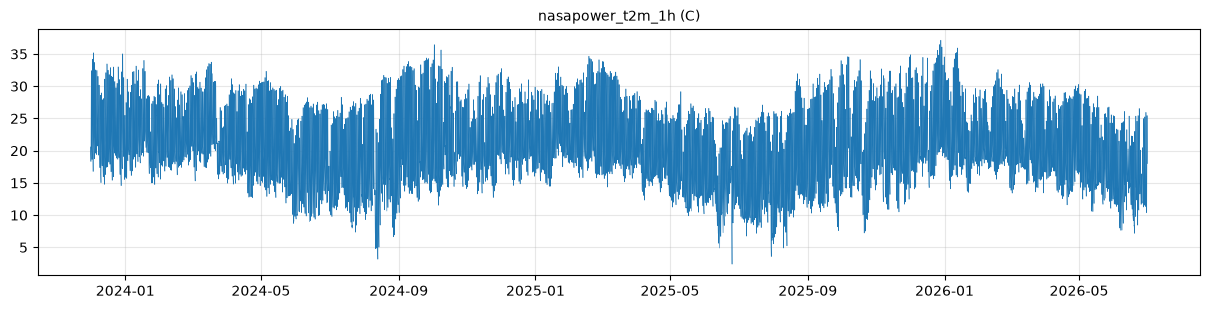

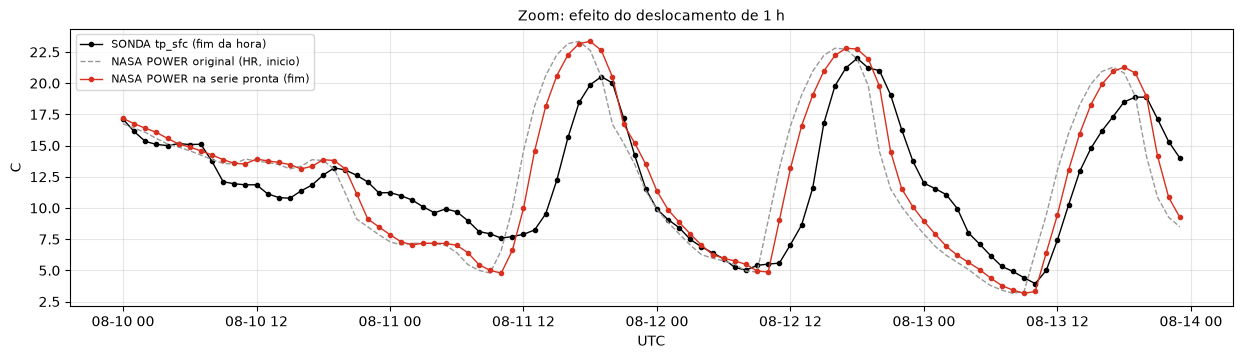

In [5]:
relida = motor.carregar_serie_pronta(NOME_SERIE)
print("Passo detectado pelo motor:", motor.detectar_passo(relida), "| NaN:", int(relida.isna().sum()))

fig, eixo = plt.subplots(figsize=(15, 3.2))
eixo.plot(relida.index, relida.values, lw=0.4)
eixo.set_title(f"{NOME_SERIE} ({unidade})", fontsize=10)
eixo.grid(True, alpha=0.3)
plt.show()

ZOOM = ("2024-08-10", "2024-08-13")
sonda_tp = motor.carregar_serie_pronta("sonda_tp_sfc_1h")
fig, eixo = plt.subplots(figsize=(15, 3.6))
eixo.plot(sonda_tp.loc[ZOOM[0]:ZOOM[1]], "k-o", ms=3, lw=1, label="SONDA tp_sfc (fim da hora)")
eixo.plot(serie_bruta.loc[ZOOM[0]:ZOOM[1]], "--", color="0.6", lw=1, label="NASA POWER original (HR, inicio)")
eixo.plot(relida.loc[ZOOM[0]:ZOOM[1]], "-o", color="#d7301f", ms=3, lw=1, label="NASA POWER na serie pronta (fim)")
eixo.set_ylabel(unidade)
eixo.set_xlabel("UTC")
eixo.legend(fontsize=8)
eixo.grid(True, alpha=0.3)
eixo.set_title("Zoom: efeito do deslocamento de 1 h", fontsize=10)
plt.show()